In [464]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import random
from scipy.stats import weibull_min

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 15})

## reflektor 1D

In [314]:
def sipanje_1D(L,lega,pp):
    '''R=radij kroga, pp=prosta pot delcev'''
    prepust=0
    n=0 #št sipanj
    while prepust == 0:
        smer= random.choice([-1,1]) #+naprej, -nazaj
        dolžina = np.random.exponential(scale=pp) # pot delčka
        lega += smer*dolžina
        if lega > L:
            prepust = 1 #prepuščen
        elif lega < 0:
            prepust=-1 #odboj
        else:
            n+=1 #sipanje
    return prepust, n
def sipanje_zač(L,lega,pp):
    '''začetek sipanje le naprej!'''
    prepust=0
    n=0 #št sipanj
    dolžina = np.random.exponential(scale=pp) # pot delčka
    lega += dolžina
    if lega > L:
        prepust = 1 #prepuščen
    #elif lega < 0:
        #print('to ni možno!')
        #prepust=-1 #odboj
    else:
        n+=1 #sipanje
    return prepust, n, lega
def delec_1D(L,pp, N): #pazi začetne odboje
    '''L=dolžina medija, pp=povpr. prosta pot, N=št. delcev'''
    prepuščeni=0
    odbiti=0
    N=int(N)
    sipanja=np.zeros(N)
    for delec in range(N):
        lega=0 #začetna
        prepust, n, lega = sipanje_zač(L,lega,pp)            
        if prepust ==1:
            prepuščeni+=1
            sipanja[delec] = n
        # elif prepust == -1: #nemogoče za dane ZP
        #     odbiti+=1
        #     sipanja[delec] = n
        else:
            prepust, n = sipanje_1D(L,lega,pp)
            if prepust ==1:
                prepuščeni+=1
                sipanja[delec] = n
            elif prepust == -1:
                odbiti+=1
                sipanja[delec] = n
    return prepuščeni, odbiti, sipanja

In [315]:
L=1
pp= 10#=pp/L
N=10000
p,o,n=delec_1D(L,pp,N)
p,o

(9550, 450)

In [380]:
L=1
pp= 0.5#=pp/L
N=10000
N0=np.logspace(3,6,4*4)
prepuščeni=[]
odbiti=[]
n_sip=[]
for N in N0:
    p,o,n=delec_1D(L,pp,N)
    prepuščeni.append(p)
    odbiti.append(o)
    n_sip.append(n)
prepuščeni=np.array(prepuščeni)
odbiti=np.array(odbiti)

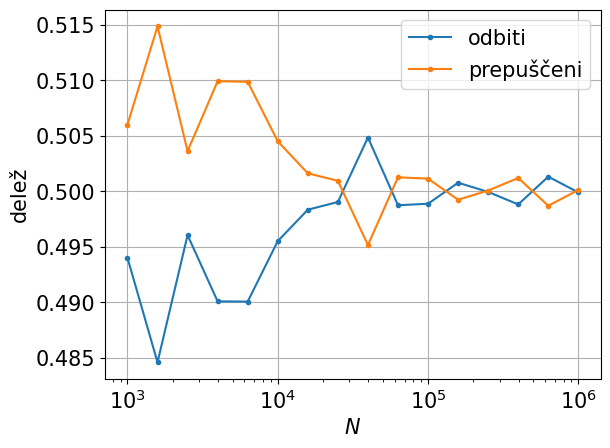

In [384]:
plt.plot(N0,prepuščeni/N0,'.-',label='odbiti')
plt.plot(N0,odbiti/N0,'.-',label='prepuščeni')
plt.xscale('log')
plt.legend()
plt.grid()
plt.xlabel('$N$')
plt.ylabel('delež')
#plt.savefig('slike/nevtroni_N.pdf',bbox_inches='tight')

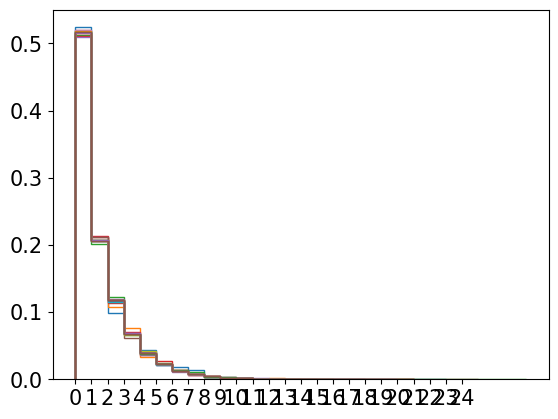

In [385]:
for i in range(len(n_sip)):
    plt.hist(n_sip[i],bins=int(np.max(n_sip[i])), histtype='step',density=True)
plt.xticks(list(np.arange(0,np.max(n_sip[i]))))
plt.show()

## sprememba proste poti

In [336]:
L=1
pp= 0.1 #=pp/L
pp0=np.logspace(-2,2,20)
N=20000
prepuščeni=[]
odbiti=[]
n_sip1=[]
for pp in pp0:
    p,o,n=delec_1D(L,pp,N)
    prepuščeni.append(p)
    odbiti.append(o)
    n_sip1.append(n)
prepuščeni_1=np.array(prepuščeni)
odbiti_1=np.array(odbiti)

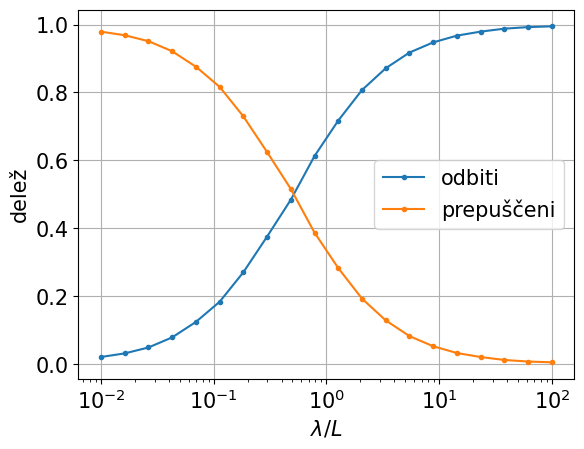

In [378]:
plt.plot(pp0,prepuščeni_1/N,'.-',label='odbiti') #zakaj obratno!!!???
plt.plot(pp0,odbiti_1/N,'.-',label='prepuščeni')
plt.xscale('log')
plt.legend()
plt.grid()
plt.xlabel('$\lambda/L$')
plt.ylabel('delež')
#plt.savefig('slike/nevtroni_pp.pdf',bbox_inches='tight')

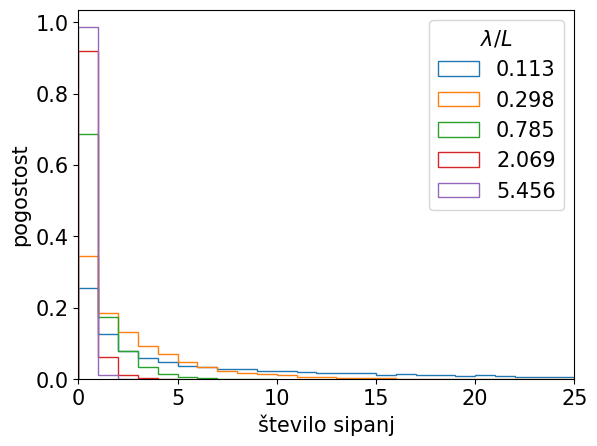

In [396]:
for i in range(5,14,2):
    plt.hist(n_sip1[i],bins=int(np.max(n_sip1[i])), histtype='step',density=True,label=str(round(pp0[i],3)))
#plt.xticks(list(np.arange(0,np.max(n_sip[i]))))
plt.legend(title='$\lambda/L$')
plt.xlim((0,25))
plt.xlabel('število sipanj')
plt.ylabel('pogostost')
#plt.savefig('slike/nevtroni_porazd_pp.pdf',bbox_inches='tight')

## 2d primer

In [320]:
def sipanje_2D(L,lega,pp):
    '''R=radij kroga, pp=prosta pot delcev'''
    prepust=0
    n=0 #št sipanj
    while prepust == 0:
        kot = 2*np.pi*np.random.random()
        dolžina = np.random.exponential(scale=pp) # pot delčka
        lega += dolžina*np.cos(kot)
        if lega > L:
            prepust = 1 #prepuščen
        elif lega < 0:
            prepust=-1 #odboj
        else:
            n+=1 #sipanje
    return prepust, n
def sipanje_zač_2D(L,lega,pp):
    '''začetek sipanje le naprej!'''
    prepust=0
    n=0 #št sipanj
    kot = np.random.uniform(-np.pi/2, np.pi/2) #le navznoter!
    dolžina = np.random.exponential(scale=pp) # pot delčka
    lega += dolžina*np.cos(kot)
    if lega > L:
        prepust = 1 #prepuščen
    #elif lega < 0:
        #print('to ni možno!')
        #prepust=-1 #odboj
    else:
        n+=1 #sipanje
    return prepust, n, lega
def delec_2D(L,pp, N): #pazi začetne odboje
    '''L=dolžina medija, pp=povpr. prosta pot, N=št. delcev'''
    prepuščeni=0
    odbiti=0
    N=int(N)
    sipanja=np.zeros(N)
    for delec in range(N):
        lega=0 #začetna
        prepust, n, lega = sipanje_zač_2D(L,lega,pp)            
        if prepust ==1:
            prepuščeni+=1
            sipanja[delec] = n
        # elif prepust == -1: #nemogoče za dane ZP
        #     odbiti+=1
        #     sipanja[delec] = n
        else:
            prepust, n = sipanje_2D(L,lega,pp)
            if prepust ==1:
                prepuščeni+=1
                sipanja[delec] = n
            elif prepust == -1:
                odbiti+=1
                sipanja[delec] = n
    return prepuščeni, odbiti, sipanja

In [339]:
L=1
pp= 0.1 #=pp/L
pp0=np.logspace(-2,2,20)
N=20000
prepuščeni=[]
odbiti=[]
n_sip2=[]
for pp in pp0:
    p,o,n=delec_2D(L,pp,N)
    prepuščeni.append(p)
    odbiti.append(o)
    n_sip2.append(n)
prepuščeni_2=np.array(prepuščeni)
odbiti_2=np.array(odbiti)

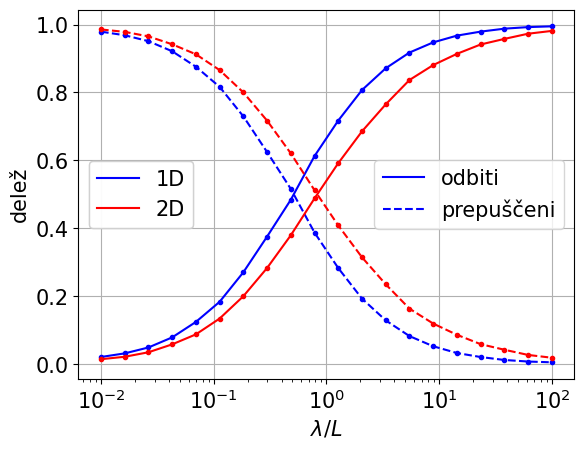

In [371]:
plt.plot(pp0,prepuščeni_1/N,'b.-',label='odbiti') #zakaj obratno!!!???
plt.plot(pp0,odbiti_1/N,'b.--',label='prepuščeni')
plt.plot(pp0,prepuščeni_2/N,'r.-',label='odbiti 2D') #zakaj obratno!!!???
plt.plot(pp0,odbiti_2/N,'r.--',label='prepuščeni 2D')
plt.xscale('log')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='b', linestyle='-', label='odbiti'),
                                         plt.Line2D([], [], color='b', linestyle='--', label='prepuščeni')],
                                loc='right', ncol=1)
plt.gca().add_artist(legend_line_styles)  # Add this to keep the first legend while adding the second one
legend_colors = plt.legend(handles=[plt.Line2D([], [], color='b', label='1D'),
                                     plt.Line2D([], [], color='r', label='2D')],
                           loc='center left', ncol=1)
plt.gca().add_artist(legend_colors)  # Add the second legend after the first one
#plt.legend()
plt.grid()
plt.xlabel('$\lambda/L$')
plt.ylabel('delež')
#plt.savefig('slike/nevtroni_pp_2D.pdf',bbox_inches='tight')

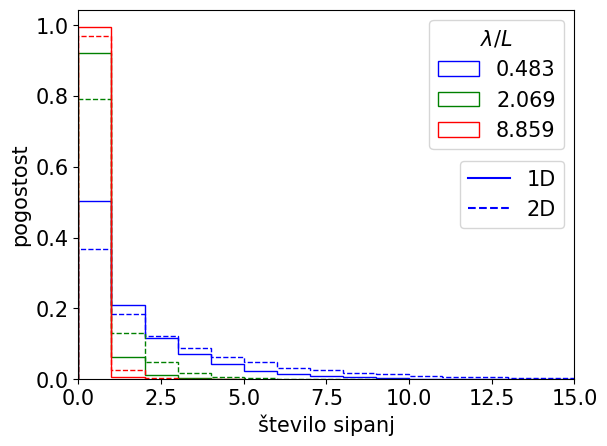

In [398]:
colors=['b','g','r','c','m','y','k']
j=0
for i in range(8,15,3):
    plt.hist(n_sip1[i],bins=int(np.max(n_sip1[i])),color=colors[j], histtype='step',density=True,label=str(round(pp0[i],3)))
    plt.hist(n_sip2[i],bins=int(np.max(n_sip2[i])),color=colors[j],linestyle='dashed', histtype='step',density=True)
    j+=1
#plt.xticks(list(np.arange(0,np.max(n_sip[i]))))
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='b', linestyle='-', label='1D'),
                                         plt.Line2D([], [], color='b', linestyle='--', label='2D')],
                                loc='right', ncol=1)
plt.gca().add_artist(legend_line_styles)
plt.legend(title='$\lambda/L$')
plt.xlim((0,15))
plt.xlabel('število sipanj')
plt.ylabel('pogostost')
#plt.savefig('slike/nevtroni_porazd_2_1D.pdf',bbox_inches='tight')

## 3D sipanje

In [400]:
def sipanje_3D(L,lega,pp):
    '''R=radij kroga, pp=prosta pot delcev'''
    prepust=0
    n=0 #št sipanj
    while prepust == 0:
        kot1 = 2*np.pi*np.random.random()
        kot2 = 2*np.pi*np.random.random()
        dolžina = np.random.exponential(scale=pp) # pot delčka
        lega += dolžina*np.cos(kot1)*np.cos(kot2)
        if lega > L:
            prepust = 1 #prepuščen
        elif lega < 0:
            prepust=-1 #odboj
        else:
            n+=1 #sipanje
    return prepust, n
def sipanje_zač_3D(L,lega,pp):
    '''začetek sipanje le naprej!'''
    prepust=0
    n=0 #št sipanj
    kot1 = np.random.uniform(-np.pi/2, np.pi/2) #le navznoter!
    kot2 = np.random.uniform(-np.pi/2, np.pi/2)
    dolžina = np.random.exponential(scale=pp) # pot delčka
    lega += dolžina*np.cos(kot1)*np.cos(kot2)
    if lega > L:
        prepust = 1 #prepuščen
    #elif lega < 0:
        #print('to ni možno!')
        #prepust=-1 #odboj
    else:
        n+=1 #sipanje
    return prepust, n, lega
def delec_3D(L,pp, N): #pazi začetne odboje
    '''L=dolžina medija, pp=povpr. prosta pot, N=št. delcev'''
    prepuščeni=0
    odbiti=0
    N=int(N)
    sipanja=np.zeros(N)
    for delec in range(N):
        lega=0 #začetna
        prepust, n, lega = sipanje_zač_3D(L,lega,pp)            
        if prepust ==1:
            prepuščeni+=1
            sipanja[delec] = n
        # elif prepust == -1: #nemogoče za dane ZP
        #     odbiti+=1
        #     sipanja[delec] = n
        else:
            prepust, n = sipanje_3D(L,lega,pp)
            if prepust ==1:
                prepuščeni+=1
                sipanja[delec] = n
            elif prepust == -1:
                odbiti+=1
                sipanja[delec] = n
    return prepuščeni, odbiti, sipanja

In [401]:
L=1
pp= 0.1 #=pp/L
pp0=np.logspace(-2,2,20)
N=20000
prepuščeni=[]
odbiti=[]
n_sip3=[]
for pp in pp0:
    p,o,n=delec_3D(L,pp,N)
    prepuščeni.append(p)
    odbiti.append(o)
    n_sip3.append(n)
prepuščeni_3=np.array(prepuščeni)
odbiti_3=np.array(odbiti)

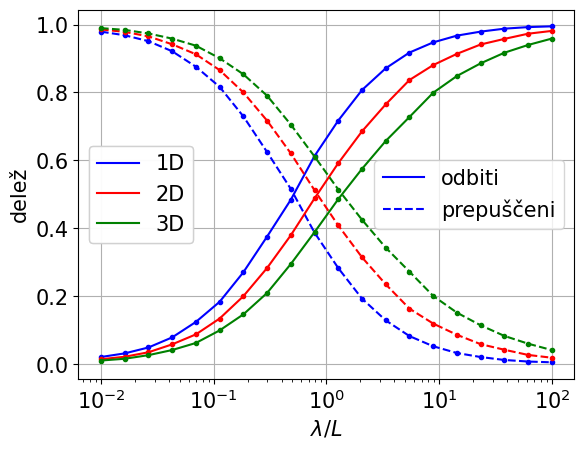

In [403]:
plt.plot(pp0,prepuščeni_1/N,'b.-',label='odbiti') #zakaj obratno!!!???
plt.plot(pp0,odbiti_1/N,'b.--',label='prepuščeni')
plt.plot(pp0,prepuščeni_2/N,'r.-',label='odbiti 2D') #zakaj obratno!!!???
plt.plot(pp0,odbiti_2/N,'r.--',label='prepuščeni 2D')
plt.plot(pp0,prepuščeni_3/N,'g.-',label='odbiti 3D') #zakaj obratno!!!???
plt.plot(pp0,odbiti_3/N,'g.--',label='prepuščeni 3D')
plt.xscale('log')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='b', linestyle='-', label='odbiti'),
                                         plt.Line2D([], [], color='b', linestyle='--', label='prepuščeni')],
                                loc='right', ncol=1)
plt.gca().add_artist(legend_line_styles)  # Add this to keep the first legend while adding the second one
legend_colors = plt.legend(handles=[plt.Line2D([], [], color='b', label='1D'),
                                     plt.Line2D([], [], color='r', label='2D'),
                                     plt.Line2D([], [], color='g', label='3D')],
                           loc='center left', ncol=1)
plt.gca().add_artist(legend_colors)  # Add the second legend after the first one
#plt.legend()
plt.grid()
plt.xlabel('$\lambda/L$')
plt.ylabel('delež')
#plt.savefig('slike/nevtroni_pp_3D.pdf',bbox_inches='tight')

# nove porazdelitve

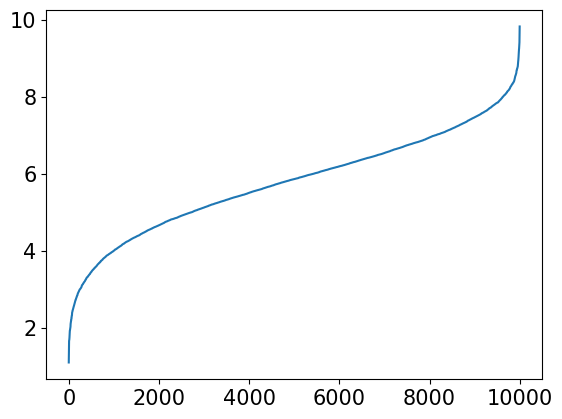

In [463]:
kot1 = 2*np.pi*np.random.weibull(5,size=10000)
plt.plot(sorted(kot1))

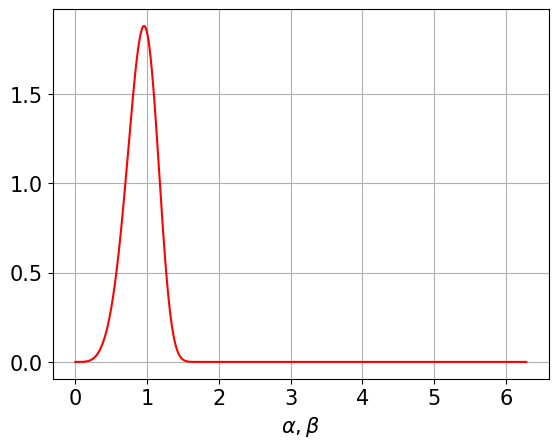

In [474]:
# Define parameters
shape = 5  # Shape parameter (k)
scale = 1  # Scale parameter (lambda)

# Generate data from Weibull distribution
x = np.linspace(0, 2*np.pi, 1000)  # Range of x values
pdf = weibull_min.pdf(x, shape, scale=scale)  # Probability Density Function (PDF)

# Plot the Weibull distribution
#plt.figure(figsize=(8, 6))
plt.plot(x, pdf, 'r-', label=f'Weibull (k={shape}, scale={scale})')
plt.xlabel('$\\alpha,\\beta$')
#plt.ylabel('Probability Density')
#plt.legend()
plt.grid()
plt.show()

In [489]:
def sipanje_n(L,lega,pp):
    '''R=radij kroga, pp=prosta pot delcev'''
    prepust=0
    n=0 #št sipanj
    while prepust == 0:
        kot1 = 2*np.pi*np.random.weibull(10)
        kot2 = 2*np.pi*np.random.weibull(10)
        dolžina = np.random.exponential(scale=pp) # pot delčka
        lega += dolžina*np.cos(kot1)*np.cos(kot2)
        if lega > L:
            prepust = 1 #prepuščen
        elif lega < 0:
            prepust=-1 #odboj
        else:
            n+=1 #sipanje
    return prepust, n
def sipanje_zač_n(L,lega,pp):
    '''začetek sipanje le naprej!'''
    prepust=0
    n=0 #št sipanj
    kot1 = np.random.uniform(-np.pi/2, np.pi/2) #le navznoter!
    kot2 = np.random.uniform(-np.pi/2, np.pi/2)
    dolžina = np.random.exponential(scale=pp) # pot delčka
    lega += dolžina*np.cos(kot1)*np.cos(kot2)
    if lega > L:
        prepust = 1 #prepuščen
    #elif lega < 0:
        #print('to ni možno!')
        #prepust=-1 #odboj
    else:
        n+=1 #sipanje
    return prepust, n, lega
def delec_n(L,pp, N): #pazi začetne odboje
    '''L=dolžina medija, pp=povpr. prosta pot, N=št. delcev'''
    prepuščeni=0
    odbiti=0
    N=int(N)
    sipanja=np.zeros(N)
    for delec in range(N):
        lega=0 #začetna
        prepust, n, lega = sipanje_zač_n(L,lega,pp)            
        if prepust ==1:
            prepuščeni+=1
            sipanja[delec] = n
        # elif prepust == -1: #nemogoče za dane ZP
        #     odbiti+=1
        #     sipanja[delec] = n
        else:
            prepust, n = sipanje_n(L,lega,pp)
            if prepust ==1:
                prepuščeni+=1
                sipanja[delec] = n
            elif prepust == -1:
                odbiti+=1
                sipanja[delec] = n
    return prepuščeni, odbiti, sipanja

In [490]:
L=1
pp= 0.1 #=pp/L
pp0=np.logspace(-2,2,20)
N=20000
prepuščeni=[]
odbiti=[]
n_sip_n=[]
for pp in pp0:
    p,o,n=delec_n(L,pp,N)
    prepuščeni.append(p)
    odbiti.append(o)
    n_sip_n.append(n)
prepuščeni_n=np.array(prepuščeni)
odbiti_n=np.array(odbiti)

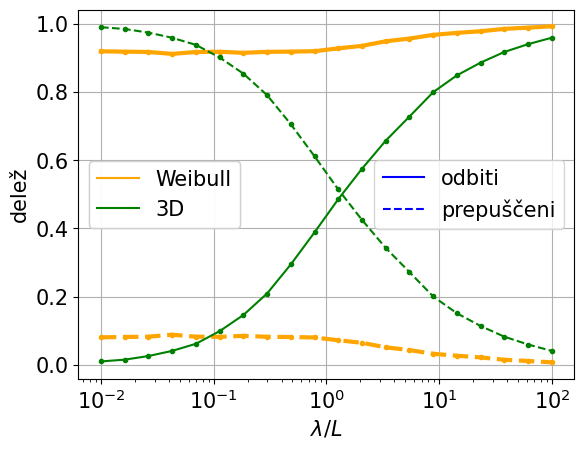

In [493]:
plt.plot(pp0,prepuščeni_n/N,'.-',label='odbiti', linewidth=3, color='orange') #zakaj obratno!!!???
plt.plot(pp0,odbiti_n/N,'.--',label='prepuščeni', linewidth=3, color='orange')
plt.plot(pp0,prepuščeni_3/N,'g.-',label='odbiti 3D') #zakaj obratno!!!???
plt.plot(pp0,odbiti_3/N,'g.--',label='prepuščeni 3D')
plt.xscale('log')
legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='b', linestyle='-', label='odbiti'),
                                         plt.Line2D([], [], color='b', linestyle='--', label='prepuščeni')],
                                loc='right', ncol=1)
plt.gca().add_artist(legend_line_styles)  # Add this to keep the first legend while adding the second one
legend_colors = plt.legend(handles=[plt.Line2D([], [], color='orange', label='Weibull'),
                                     plt.Line2D([], [], color='g', label='3D')],
                           loc='center left', ncol=1)
plt.gca().add_artist(legend_colors)  # Add the second legend after the first one
#plt.legend()
plt.grid()
plt.xlabel('$\lambda/L$')
plt.ylabel('delež')
#plt.savefig('slike/nevtroni_pp_w10.pdf',bbox_inches='tight')

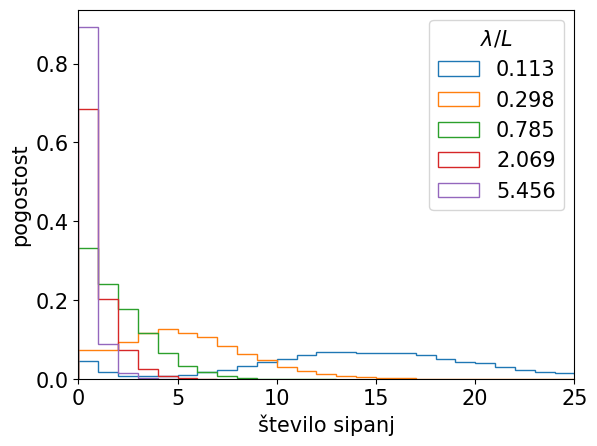

In [495]:
for i in range(5,14,2):
    plt.hist(n_sip_n[i],bins=int(np.max(n_sip_n[i])), histtype='step',density=True,label=str(round(pp0[i],3)))
#plt.xticks(list(np.arange(0,np.max(n_sip[i]))))
plt.legend(title='$\lambda/L$')
plt.xlim((0,25))
plt.xlabel('število sipanj')
plt.ylabel('pogostost')
#plt.savefig('slike/nevtroni_porazd_pp_w10.pdf',bbox_inches='tight')